# What should `REGEX_UNITS_PER_STEP` be for the Python dialect?

The Python dialect's step budget is `_restricted.DEFAULT_BUDGET` = 15,000,000 steps, calibrated to about one second. An
sre search (`re.search`, `re.findall`) is one host call whose work the step count never sees, so the checker prices it
first: `regex_work(pattern, flags, string)` (`Lib/restricted.py` in the fork, the Python port of window-ml's
`regexWork`) is an upper bound, in units of about one backtracking step, and `regex_steps` charges it at
`REGEX_UNITS_PER_STEP` units a step. Counted repeats (`{m,n}` with a finite n) are weighted by `_COUNTED_LOOP_WEIGHT`
inside the bound.

The constant is sound when the time a search costs, `ns per unit x units`, is at most the time its charged steps are
worth, `ns per step x steps`, for every search. That is `REGEX_UNITS_PER_STEP <= ns per step / (slowest ns per unit)`.

Everything is measured in Pyodide on the restricted-mode fork core (wasm32), because that is where `python_exec` runs.
Four groups, as in the JS calibration (`notebooks/readonly/regex-cost.ipynb`): worst-case shapes (eighteen of the
JS twenty: `\p{L}` and the variable-width lookbehind do not exist in `re`), counted repeats at up to 2M characters, ten
ordinary surveys, and seeded random patterns that pass BOTH `risky_regex` and `risky_parse`, on six adversarial inputs.

Re-run: `NB_REFRESH=1 node scripts/nb.mjs run notebooks/python-dialect/regex-cost.ipynb`, which runs
`node notebooks/python-dialect/regex-cost/one.mjs pyodide-core <restricted.py>` from the repo root.

In [1]:
import json, os, re, subprocess
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import wmlnb

HERE = wmlnb.ROOT / "notebooks" / "python-dialect"
EXTRACT = HERE / "data" / "regex-cost" / "bench.json"
RESTRICTED_PY = os.environ.get("REGEX_RESTRICTED_PY", os.path.expanduser("~/git/cpython-pycancel/Lib/restricted.py"))
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 50)

def run_bench():
    out = subprocess.run(["node", "notebooks/python-dialect/regex-cost/one.mjs", "pyodide-core", RESTRICTED_PY],
                         cwd=wmlnb.ROOT, capture_output=True, text=True, check=True)
    return json.loads(out.stdout)

data = wmlnb.extract(EXTRACT, run_bench, source={"driver": "notebooks/python-dialect/regex-cost/one.mjs",
                     "cmd": "node notebooks/python-dialect/regex-cost/one.mjs pyodide-core <fork Lib/restricted.py>"})
meta, step_rate = data["meta"], data["step_rate"]
UNITS_PER_STEP_NOW = meta["REGEX_UNITS_PER_STEP"]
WEIGHT = meta["COUNTED_LOOP_WEIGHT"]
df = pd.DataFrame(data["rows"])
bad = df[df.ns_per_unit.isna()]
df = df[df.ns_per_unit.notna()].copy()
pd.DataFrame(wmlnb.provenance(EXTRACT))

,extract,sha256,rows,extracted_at,commit,cmd,driver
0,notebooks/python-dialect/data/regex-cost/bench...,b3530c61156635e4,3,2026-10-27T16:49:05+00:00,87a51ca8272d,node notebooks/python-dialect/regex-cost/one.m...,notebooks/python-dialect/regex-cost/one.mjs


## The machine

Load from other processes slows the timed search AND the step loops alike, so ns per unit over ns per step moves much
less than either alone; both are reported with the load average.

In [2]:
pd.Series({
    "pyodide": meta["pyodide"], "python": meta["python"][:40], "platform": meta["platform"], "node": meta["node"],
    "cpu": meta["cpus"], "cpus": meta["cpu_count"],
    "loadavg at start (1/5/15 min)": [round(x, 2) for x in meta["loadavg_start"]],
    "loadavg at end": [round(x, 2) for x in meta["loadavg_end"]],
    "run took (s)": meta["seconds"], "date": meta["date"],
    "REGEX_UNITS_PER_STEP in the fork file": UNITS_PER_STEP_NOW, "_COUNTED_LOOP_WEIGHT": WEIGHT,
    "rows": len(df), "rows with an error or no bound": len(bad),
}).to_frame("value")

,value
pyodide,314.0.3
python,"3.14.2 (main, Oct 24 2026, 14:53:03) [Cl"
platform,emscripten
node,v26.12.1
cpu,Apple M5 Pro
cpus,15
loadavg at start (1/5/15 min),"[9.0, 7.08, 7.36]"
loadavg at end,"[14.21, 9.49, 8.26]"
run took (s),125
date,2026-10-27T16:47:01Z


## The interpreter's step rate

CPU-bound cells through `restricted.run_cell(src, ns, budget=...)`, timed with `time.perf_counter`; steps are what
`_restricted.steps()` reports for the finished run. Five runs per cell after a warm-up. (A `while` loop is not in the
dialect, so the second cell is a branch in a `for`.) Cells differ in how much C work a step covers: a call of the cell's
own `def` is the fastest per step, so it is the strict basis (fewest ns a step is worth).

In [3]:
cells = {k: v for k, v in step_rate.items() if isinstance(v, dict) and "rates" in v}
rate_tab = pd.DataFrame({k: {"steps per run": v["steps"], "median steps/s": np.median(v["rates"]),
                             "min": min(v["rates"]), "max": max(v["rates"]), "ns per step": 1e9 / np.median(v["rates"])}
                         for k, v in cells.items()}).T
RATE_MEDIAN = float(step_rate["median_steps_per_s"])
RATE_FASTEST = float(rate_tab["median steps/s"].max())
BUDGET = step_rate["default_budget"]
NS_MEDIAN, NS_FASTEST, NS_DECLARED = 1e9 / RATE_MEDIAN, 1e9 / RATE_FASTEST, 1e9 / BUDGET
print(f"median over all runs: {RATE_MEDIAN:,.0f} steps/s = {NS_MEDIAN:.1f} ns per step  (DEFAULT_BUDGET {BUDGET:,} steps = {BUDGET / RATE_MEDIAN:.2f} s)")
print(f"fastest cell:         {RATE_FASTEST:,.0f} steps/s = {NS_FASTEST:.1f} ns per step  (DEFAULT_BUDGET = {BUDGET / RATE_FASTEST:.2f} s)")
print(f"declared (budget = 1 s): {NS_DECLARED:.1f} ns per step")
rate_tab.round(1)

median over all runs: 7,073,902 steps/s = 141.4 ns per step  (DEFAULT_BUDGET 15,000,000 steps = 2.12 s)
fastest cell:         13,632,524 steps/s = 73.4 ns per step  (DEFAULT_BUDGET = 1.10 s)
declared (budget = 1 s): 66.7 ns per step


,steps per run,median steps/s,min,max,ns per step
branch,1000006.0,7538941.2,7394090.0,7779897.7,132.6
def_call,600006.0,13632523.6,13440455.1,14046043.4,73.4
for_add,1000006.0,5126098.9,3836058.7,6348134.4,195.1
list_append,1000007.0,6696378.3,6015070.7,6753714.3,149.3


## ns per unit of bound, by group

`ns_per_unit` is the median of three timings (one when the first exceeded 500 ms) over the bound `regex_work`
returns. A pattern is `counted` when it holds a finite counted repeat (`{n}`, `{m,n}`, `{,n}`), `unbounded` otherwise
(`*`, `+`, `?`, `{m,}`); the counted weight is checked on the first.

In [4]:
FINITE = re.compile(r"\{\d+\}|\{\d*,\d+\}")
df["repeat"] = np.where(df.pattern.map(lambda p: bool(FINITE.search(p))), "counted", "unbounded")
g = df.groupby("group").ns_per_unit
print("by group")
display((pd.DataFrame({"max": g.max(), "p95": g.quantile(0.95), "median": g.median(), "count": g.count()})
   .reindex(["worst", "counted", "ordinary", "fuzz"]).round(3)))
g = df.groupby("repeat").ns_per_unit
print("by repeat kind")
display(pd.DataFrame({"max": g.max(), "p95": g.quantile(0.95), "median": g.median(), "count": g.count()}).round(3))

by group


,max,p95,median,count
group,,,,
worst,2.534,2.289,0.106,18
counted,3.694,3.374,1.687,6
ordinary,4.223,3.782,0.988,10
fuzz,21.500,4.138,1.364,241


by repeat kind


,max,p95,median,count
repeat,,,,
counted,21.500,4.233,0.804,137
unbounded,6.289,3.829,1.611,138


The twelve rows with the highest ns per unit, across all groups.

In [5]:
cols = ["group", "repeat", "pattern", "flags", "method", "n", "input", "ms", "units", "results", "ns_per_unit"]
top = df.sort_values("ns_per_unit", ascending=False).head(12)
top[cols].assign(ms=lambda d: d.ms.round(2), units=lambda d: d.units.map("{:.2e}".format), ns_per_unit=lambda d: d.ns_per_unit.round(3))

,group,repeat,pattern,flags,method,n,input,ms,units,results,ns_per_unit
250,fuzz,counted,"(?:a{0,50}\w(a)+|[ab])?(?=a)+(?=a)?",0,findall,3000,'ababababababab',2.19,1.02e+05,2999.0,21.500
211,fuzz,counted,(?!b)?(?!b)+[ab]*?(?:(a)*?|(?:ab){3}(a)*)?,0,findall,3000,' ',2.29,1.71e+05,3001.0,13.403
213,fuzz,counted,(?!b)?(?!b)+[ab]*?(?:(a)*?|(?:ab){3}(a)*)?,0,findall,3000,'11111111111111',2.10,1.71e+05,3001.0,12.277
187,fuzz,counted,"(?=a){2,}(a){0,50}\s{2,}\d*?",0,findall,3000,'aaaaaaaaaaaaaa',10.92,1.53e+06,0.0,7.124
188,fuzz,counted,"(?=a){2,}(a){0,50}\s{2,}\d*?",0,findall,3000,'aaaaaaaaaaaaaa',10.50,1.53e+06,0.0,6.844
196,fuzz,unbounded,(a)+(?=a)?\d+(?=a),S,findall,3000,'aaaaaaaaaaaaaa',566.24,9.00e+07,0.0,6.289
251,fuzz,counted,".{3}a{0,50}(a)?\s",M,findall,3000,'aaaaaaaaaaaaaa',7.64,1.56e+06,0.0,4.893
197,fuzz,unbounded,(a)+(?=a)?\d+(?=a),S,findall,3000,'aaaaaaaaaaaaaa',422.36,9.00e+07,0.0,4.693
193,fuzz,unbounded,"\s{2,}(?=a)*\w+?",S,findall,3000,' ',210.35,4.50e+07,0.0,4.674
252,fuzz,counted,".{3}a{0,50}(a)?\s",M,findall,3000,'aaaaaaaaaaaaaa',7.19,1.56e+06,0.0,4.610


## What the slow rows are: `findall` builds a result per match

The bound prices backtracking; it does not price building the list `findall` returns. A pattern that matches the empty
string at every position of a 3000-character input produces about 3000 results, and the 1 to 2 ms that costs sits on a
bound of only 1e5 units, which is why the tiny fuzz rows top the table. The cost of one result is estimated as the LOWEST
ms per result over the rows with at least 1000 results (the least contaminated by backtracking); `net` subtracts it.
`ns_per_unit_best` uses the fastest of every timing taken of the row (the three runs, and the 21-run retime of the
slowest rows), so a stall from machine load, which only ever adds time, cannot set the maximum.

In [6]:
f = df[(df.method == "findall") & (df.results >= 1000)]
RESULT_NS = float((f.ms * 1e6 / f.results).min())
print(f"{len(f)} findall rows with >= 1000 results; lowest ms per result = {RESULT_NS:.0f} ns/result (median {(f.ms * 1e6 / f.results).median():.0f})")
df["ms_net"] = (df.ms - df.results.fillna(0) * RESULT_NS * 1e-6).clip(lower=0)
df["ns_per_unit_net"] = df.ms_net * 1e6 / df.units
df["ms_best"] = df[["ms", "ms_min", "ms_retimed_min"]].min(axis=1)
df["ns_per_unit_best"] = df.ms_best * 1e6 / df.units
df["ns_per_unit_best_net"] = (df.ms_best - df.results.fillna(0) * RESULT_NS * 1e-6).clip(lower=0) * 1e6 / df.units
cols = ["ns_per_unit", "ns_per_unit_best", "ns_per_unit_net", "ns_per_unit_best_net"]
g = df.groupby("repeat")[cols].max()
g.loc["all"] = df[cols].max()
print("max ns/unit by repeat kind: as timed (median of 3), best of all timings, and each net of the findall result list")
g.round(3)

18 findall rows with >= 1000 results; lowest ms per result = 115 ns/result (median 700)
max ns/unit by repeat kind: as timed (median of 3), best of all timings, and each net of the findall result list


,ns_per_unit,ns_per_unit_best,ns_per_unit_net,ns_per_unit_best_net
repeat,,,,
counted,21.500,12.516,18.105,10.490
unbounded,6.289,6.289,6.289,6.289
all,21.500,12.516,18.105,10.490


## The derived constant

`ns per step / slowest ns per unit` is the most units a step may be charged for if the slowest measured search is to
just fit its charge. Bases: the median step rate, the fastest cell's rate, the declared one-second budget; and the
slowest row as timed (median of three), at its best timing, or net of the result list. A candidate power of two is the largest not above the derived value;
its margin is derived / candidate (1.0 means the slowest row just fits; the shipped value is shown too).

In [7]:
def pow2_floor(x):
    return 2 ** int(np.floor(np.log2(x)))

SLOW = {"as timed": df.ns_per_unit.max(), "best of all": df.ns_per_unit_best.max(), "net of results": df.ns_per_unit_net.max(), "best, net": df.ns_per_unit_best_net.max()}
BASES = {"median rate": NS_MEDIAN, "fastest cell": NS_FASTEST, "declared 15M/s": NS_DECLARED}
rows = []
for bn, ns_step in BASES.items():
    for sn, slow in SLOW.items():
        d = ns_step / slow
        c = pow2_floor(d)
        rows.append({"ns/step basis": bn, "ns/step": round(ns_step, 1), "slowest row": sn, "ns/unit": round(slow, 3),
                     "derived units/step": round(d, 2), "pow2 candidate": c, "margin (derived/candidate)": round(d / c, 2),
                     "margin of shipped": round(d / UNITS_PER_STEP_NOW, 2)})
pd.DataFrame(rows)

,ns/step basis,ns/step,slowest row,ns/unit,derived units/step,pow2 candidate,margin (derived/candidate),margin of shipped
0,median rate,141.4,as timed,21.500,6.58,4,1.64,0.10
1,median rate,141.4,best of all,12.516,11.29,8,1.41,0.18
2,median rate,141.4,net of results,18.105,7.81,4,1.95,0.12
3,median rate,141.4,"best, net",10.490,13.48,8,1.68,0.21
4,fastest cell,73.4,as timed,21.500,3.41,2,1.71,0.05
5,fastest cell,73.4,best of all,12.516,5.86,4,1.47,0.09
6,fastest cell,73.4,net of results,18.105,4.05,4,1.01,0.06
7,fastest cell,73.4,"best, net",10.490,6.99,4,1.75,0.11
8,declared 15M/s,66.7,as timed,21.500,3.10,2,1.55,0.05
9,declared 15M/s,66.7,best of all,12.516,5.33,4,1.33,0.08


In [8]:
w = df.loc[df.ns_per_unit.idxmax()]
print(f"slowest overall : {w.ns_per_unit:.3f} ns/unit  {w.group}: {w.pattern!r} flags={w['flags']} {w.method} n={w.n} input={w.input} ({w.ms:.2f} ms, {w.units:.2e} units)")
for kind in ("counted", "unbounded"):
    d = df[df.repeat == kind]
    w = d.loc[d.ns_per_unit.idxmax()]
    print(f"slowest {kind:9s}: {w.ns_per_unit:.3f} ns/unit  {w.group}: {w.pattern!r} flags={w['flags']} {w.method} n={w.n} input={w.input} ({w.ms:.2f} ms, {w.units:.2e} units)")
    dn = d.loc[d.ns_per_unit_best_net.idxmax()]
    print(f"   best timing, net of results : {dn.ns_per_unit_best_net:.3f} ns/unit  {dn.group}: {dn.pattern!r} n={dn.n} input={dn.input}")
print()
# The strictest reading: fastest-cell ns/step over the slowest AS-TIMED row.
strict = NS_FASTEST / df.ns_per_unit.max()
print(f"strictest basis (fastest cell, slowest as timed): derived {strict:.2f}, candidate {pow2_floor(strict)}, margin {strict / pow2_floor(strict):.2f}")
print(f"shipped REGEX_UNITS_PER_STEP = {UNITS_PER_STEP_NOW}: margin {strict / UNITS_PER_STEP_NOW:.2f} on that basis ({'PASS' if strict >= UNITS_PER_STEP_NOW else 'FAIL: the slowest search costs more than its steps'})")

slowest overall : 21.500 ns/unit  fuzz: '(?:a{0,50}\\w(a)+|[ab])?(?=a)+(?=a)?' flags=0 findall n=3000 input='ababababababab' (2.19 ms, 1.02e+05 units)
slowest counted  : 21.500 ns/unit  fuzz: '(?:a{0,50}\\w(a)+|[ab])?(?=a)+(?=a)?' flags=0 findall n=3000 input='ababababababab' (2.19 ms, 1.02e+05 units)
   best timing, net of results : 10.490 ns/unit  fuzz: '(?!b)?(?!b)+[ab]*?(?:(a)*?|(?:ab){3}(a)*)?' n=3000 input='              '
slowest unbounded: 6.289 ns/unit  fuzz: '(a)+(?=a)?\\d+(?=a)' flags=S findall n=3000 input='aaaaaaaaaaaaaa' (566.24 ms, 9.00e+07 units)
   best timing, net of results : 6.289 ns/unit  fuzz: '(a)+(?=a)?\\d+(?=a)' n=3000 input='aaaaaaaaaaaaaa'

strictest basis (fastest cell, slowest as timed): derived 3.41, candidate 2, margin 1.71
shipped REGEX_UNITS_PER_STEP = 64: margin 0.05 on that basis (FAIL: the slowest search costs more than its steps)


## `_COUNTED_LOOP_WEIGHT`

If counted repeats were over-weighted, their rows would sit well below the unbounded ones in ns per unit; if
under-weighted, above. The weight is right to the extent the two maxima agree (compared at the best timing and net of the result list, since
the fuzz rows' result lists hit both kinds).

In [9]:
t = df.groupby("repeat")[["ns_per_unit", "ns_per_unit_best_net"]].agg(["max", "median"]).round(3)
c, u = df[df.repeat == "counted"].ns_per_unit_best_net.max(), df[df.repeat == "unbounded"].ns_per_unit_best_net.max()
print(f"best-timing net max: counted {c:.3f}, unbounded {u:.3f}; ratio counted/unbounded = {c / u:.2f} at weight {WEIGHT}")
print("(a ratio above 1 means the weight under-prices a counted step relative to an unbounded one: it should rise by about that factor)")
t

best-timing net max: counted 10.490, unbounded 6.289; ratio counted/unbounded = 1.67 at weight 3
(a ratio above 1 means the weight under-prices a counted step relative to an unbounded one: it should rise by about that factor)


ns_per_unit        ns_per_unit_best_net       
                  max median                  max median
repeat                                                  
counted        21.500  0.804               10.490  0.793
unbounded       6.289  1.611                6.289  1.568

## Rows the bound under-prices

A row is under-priced at a rate when its time exceeds `steps charged x ns per step` with the CURRENT
`REGEX_UNITS_PER_STEP` of the fork file. Listed for the median-rate and the fastest-cell basis.

In [10]:
d = df.copy()
d["steps"] = d.steps
for name, ns_step in (("median rate", NS_MEDIAN), ("fastest cell", NS_FASTEST)):
    d["allowed_ms"] = d.steps * ns_step * 1e-6
    d["x_over"] = d.ms / d.allowed_ms
    u = d[d.x_over > 1].sort_values("x_over", ascending=False)
    print(f"{name} ({ns_step:.1f} ns/step), REGEX_UNITS_PER_STEP={UNITS_PER_STEP_NOW}: {len(u)} of {len(d)} rows over budget")
    display(u[["group", "pattern", "flags", "method", "n", "input", "ms", "units", "steps", "results", "ns_per_unit", "x_over"]].head(12).round(3))

median rate (141.4 ns/step), REGEX_UNITS_PER_STEP=64: 65 of 275 rows over budget


,group,pattern,flags,method,n,input,ms,units,steps,results,ns_per_unit,x_over
250,fuzz,"(?:a{0,50}\w(a)+|[ab])?(?=a)+(?=a)?",0,findall,3000,'ababababababab',2.194,102033,1595,2999.0,21.500,9.729
211,fuzz,(?!b)?(?!b)+[ab]*?(?:(a)*?|(?:ab){3}(a)*)?,0,findall,3000,' ',2.293,171056,2673,3001.0,13.403,6.067
213,fuzz,(?!b)?(?!b)+[ab]*?(?:(a)*?|(?:ab){3}(a)*)?,0,findall,3000,'11111111111111',2.100,171056,2673,3001.0,12.277,5.557
187,fuzz,"(?=a){2,}(a){0,50}\s{2,}\d*?",0,findall,3000,'aaaaaaaaaaaaaa',10.925,1533510,23962,0.0,7.124,3.225
188,fuzz,"(?=a){2,}(a){0,50}\s{2,}\d*?",0,findall,3000,'aaaaaaaaaaaaaa',10.496,1533510,23962,0.0,6.844,3.099
196,fuzz,(a)+(?=a)?\d+(?=a),S,findall,3000,'aaaaaaaaaaaaaa',566.240,90033000,1406766,0.0,6.289,2.847
251,fuzz,".{3}a{0,50}(a)?\s",M,findall,3000,'aaaaaaaaaaaaaa',7.636,1560519,24384,0.0,4.893,2.215
197,fuzz,(a)+(?=a)?\d+(?=a),S,findall,3000,'aaaaaaaaaaaaaa',422.359,90002990,1406297,0.0,4.693,2.125
193,fuzz,"\s{2,}(?=a)*\w+?",S,findall,3000,' ',210.348,45005996,703219,0.0,4.674,2.116
252,fuzz,".{3}a{0,50}(a)?\s",M,findall,3000,'aaaaaaaaaaaaaa',7.194,1560519,24384,0.0,4.610,2.087


fastest cell (73.4 ns/step), REGEX_UNITS_PER_STEP=64: 145 of 275 rows over budget


,group,pattern,flags,method,n,input,ms,units,steps,results,ns_per_unit,x_over
250,fuzz,"(?:a{0,50}\w(a)+|[ab])?(?=a)+(?=a)?",0,findall,3000,'ababababababab',2.194,102033,1595,2999.0,21.500,18.749
211,fuzz,(?!b)?(?!b)+[ab]*?(?:(a)*?|(?:ab){3}(a)*)?,0,findall,3000,' ',2.293,171056,2673,3001.0,13.403,11.693
213,fuzz,(?!b)?(?!b)+[ab]*?(?:(a)*?|(?:ab){3}(a)*)?,0,findall,3000,'11111111111111',2.100,171056,2673,3001.0,12.277,10.710
187,fuzz,"(?=a){2,}(a){0,50}\s{2,}\d*?",0,findall,3000,'aaaaaaaaaaaaaa',10.925,1533510,23962,0.0,7.124,6.215
188,fuzz,"(?=a){2,}(a){0,50}\s{2,}\d*?",0,findall,3000,'aaaaaaaaaaaaaa',10.496,1533510,23962,0.0,6.844,5.971
196,fuzz,(a)+(?=a)?\d+(?=a),S,findall,3000,'aaaaaaaaaaaaaa',566.240,90033000,1406766,0.0,6.289,5.487
251,fuzz,".{3}a{0,50}(a)?\s",M,findall,3000,'aaaaaaaaaaaaaa',7.636,1560519,24384,0.0,4.893,4.269
197,fuzz,(a)+(?=a)?\d+(?=a),S,findall,3000,'aaaaaaaaaaaaaa',422.359,90002990,1406297,0.0,4.693,4.094
193,fuzz,"\s{2,}(?=a)*\w+?",S,findall,3000,' ',210.348,45005996,703219,0.0,4.674,4.078
252,fuzz,".{3}a{0,50}(a)?\s",M,findall,3000,'aaaaaaaaaaaaaa',7.194,1560519,24384,0.0,4.610,4.022


## Bound against time

Each point is one timed search. The line is the budget at the proposed strictest value (the pow2 candidate of the
strictest basis above): a point on it spends exactly its steps' worth of time; above it is under-charged.

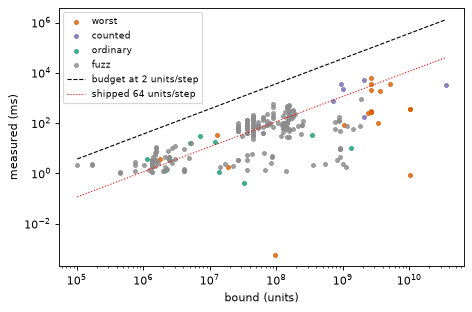

In [11]:
cand = pow2_floor(strict)
fig, ax = plt.subplots(figsize=(6, 4), dpi=80)
colors = {"worst": "#d95f02", "counted": "#7570b3", "ordinary": "#1b9e77", "fuzz": "#8c8c8c"}
for grp, col in colors.items():
    dd = df[(df.group == grp) & (df.ms > 0)]
    ax.scatter(dd.units, dd.ms, s=12, c=col, label=grp, alpha=0.8)
xs = np.array([df.units.min(), df.units.max()])
ax.plot(xs, xs / cand * NS_FASTEST * 1e-6, "k--", lw=1, label=f"budget at {cand} units/step")
ax.plot(xs, xs / UNITS_PER_STEP_NOW * NS_FASTEST * 1e-6, "r:", lw=1, label=f"shipped {UNITS_PER_STEP_NOW} units/step")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("bound (units)"); ax.set_ylabel("measured (ms)")
ax.legend(fontsize=8); fig.tight_layout()
display(fig)
plt.close(fig)

## The chosen constants: 8 units a step, and 64 units for each match a findall can return

The tables above read the bench as it was timed, with the fork file's first draft (64 units a step, no price for
results). The constants the fork sets are below, chosen on the STRICT basis (the fastest cell's step time) so that a
step charged is never worth less time than the fastest work the budget meters:

- `REGEX_UNITS_PER_STEP` = 8: the slowest row with no result list is 6.29 ns a unit (`(a)+(?=a)?\d+(?=a)`, re.S), and
  73.4 ns a step over that is 11.7 units, so 8 leaves 1.46x.
- `_RESULT_UNITS` = 64: what a match costs beyond its search (sre restarts, and builds the result), priced for every
  match a `findall` can return (at most one per start and one per shortest match). Net of each row's own units at 8 a
  step, the rows need at most the per-match time printed below; 64 units is 8 steps.

The check: every row's BEST time against the time its full charge, `(units + results x 64) / 8` steps, is worth at the
fastest step. A margin under 1 is a row the bound under-prices.

In [12]:
UNITS, RESULT_UNITS = 8, 64
d = df[df.ms_best > 0].copy()
d["res"] = d.results.fillna(0)
need = ((d.ms_best * 1e6 - d.units * NS_FASTEST / UNITS) / d.res.where(d.res > 0)).max()
print(f"per match, net of the search: at most {need:.0f} ns needed; {RESULT_UNITS} units = {RESULT_UNITS // UNITS} steps = {RESULT_UNITS / UNITS * NS_FASTEST:.0f} ns charged")
d["charged_ms"] = (d.units + d.res * RESULT_UNITS) / UNITS * NS_FASTEST * 1e-6
d["margin"] = d.charged_ms / d.ms_best
print(f"rows: {len(d)}; smallest margin {d.margin.min():.2f}; rows under 1: {(d.margin < 1).sum()}")
d.sort_values("margin")[["group", "pattern", "flags", "n", "ms_best", "units", "res", "charged_ms", "margin"]].head(8).round(3)

per match, net of the search: at most 191 ns needed; 64 units = 8 steps = 587 ns charged
rows: 275; smallest margin 1.46; rows under 1: 0


,group,pattern,flags,n,ms_best,units,res,charged_ms,margin
196,fuzz,(a)+(?=a)?\d+(?=a),S,3000,566.240,90033000,0.0,825.535,1.458
187,fuzz,"(?=a){2,}(a){0,50}\s{2,}\d*?",0,3000,9.527,1533510,0.0,14.061,1.476
188,fuzz,"(?=a){2,}(a){0,50}\s{2,}\d*?",0,3000,9.459,1533510,0.0,14.061,1.487
211,fuzz,(?!b)?(?!b)+[ab]*?(?:(a)*?|(?:ab){3}(a)*)?,0,3000,2.141,171056,3001.0,3.330,1.555
213,fuzz,(?!b)?(?!b)+[ab]*?(?:(a)*?|(?:ab){3}(a)*)?,0,3000,2.044,171056,3001.0,3.330,1.629
197,fuzz,(a)+(?=a)?\d+(?=a),S,3000,411.533,90002990,0.0,825.260,2.005
193,fuzz,"\s{2,}(?=a)*\w+?",S,3000,205.702,45005996,0.0,412.671,2.006
32,ordinary,^\s+|\s+$,0,1014000,29.917,7098006,1.0,65.084,2.175
